# 5 · Delta hedging in practice: rebalancing frequency, wrong volatility, costs, and 20 years of SPY
Black-Scholes assumes continuous hedging at a known volatility with no costs. A real hedger trades at discrete times, must guess volatility, and pays to trade. This notebook measures what each of these does to the P&L of an option writer who delta hedges:

1. **Discrete rebalancing:** how big the hedging error is, and how fast it shrinks with more frequent trading.
2. **Volatility mismatch:** what happens when realised volatility differs from the implied volatility used to price and hedge.
3. **Transaction costs:** the trade-off between hedging error and trading cost, and Leland's adjustment.
4. **Real data:** sell a one-month at-the-money SPY call every month from 2006 to 2026, price it at the VIX, delta hedge daily, and see what is left.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
IMG = pathlib.Path("../images"); DATA = pathlib.Path("../data")
from derivpricer import black_scholes as bs, hedging
S0, K, T, r, sig = 100.0, 100.0, 0.25, 0.04, 0.20
prem = bs.price(S0, K, T, r, sig)
print(f"3-month ATM call, σ = 20%: premium {prem:.3f}")

3-month ATM call, σ = 20%: premium 4.485


## 1. Hedging error vs rebalancing frequency
The writer prices and hedges at the true volatility, so the only error comes from trading at discrete times. Theory (Boyle & Emanuel, 1980; Derman & Kamal, 1999) says the standard deviation of the P&L falls like 1/√N.

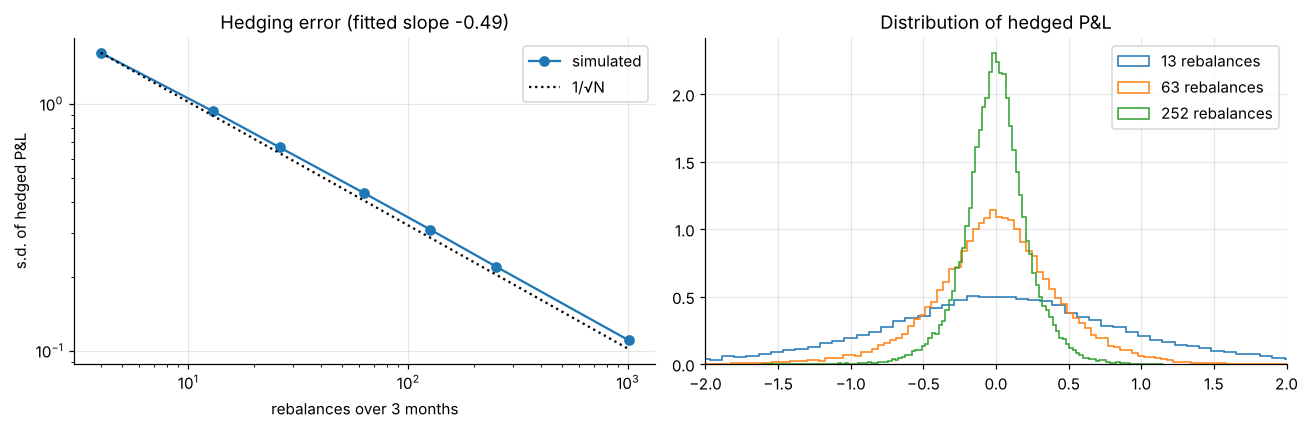

,mean P&L,s.d. of P&L,s.d. as % of premium,5% worst outcome
rebalances,,,,
4,0.002,1.612,35.941,-2.756
13,0.008,0.933,20.800,-1.531
26,0.003,0.668,14.887,-1.094
63,0.001,0.436,9.711,-0.714
126,-0.001,0.310,6.909,-0.504
252,0.001,0.219,4.881,-0.356
1008,0.000,0.110,2.458,-0.180


In [2]:
Ns = [4, 13, 26, 63, 126, 252, 1008]
res = {n: hedging.delta_hedge_pnl(S0, K, T, r, sig, n, n_paths=40_000, seed=7) for n in Ns}
tab = pd.DataFrame({"rebalances": Ns, "mean P&L": [res[n].mean() for n in Ns], "s.d. of P&L": [res[n].std() for n in Ns],
                    "s.d. as % of premium": [100 * res[n].std() / prem for n in Ns],
                    "5% worst outcome": [np.percentile(res[n], 5) for n in Ns]}).set_index("rebalances")
slope = np.polyfit(np.log(Ns), np.log(tab["s.d. of P&L"]), 1)[0]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].loglog(Ns, tab["s.d. of P&L"], "o-", label="simulated"); ax[0].loglog(Ns, tab["s.d. of P&L"].iloc[0] * np.sqrt(Ns[0] / np.array(Ns)), "k:", label="1/√N")
ax[0].set_xlabel("rebalances over 3 months"); ax[0].set_ylabel("s.d. of hedged P&L"); ax[0].set_title(f"Hedging error (fitted slope {slope:.2f})"); ax[0].legend()
for n in [13, 63, 252]: ax[1].hist(res[n], bins=120, histtype="step", density=True, label=f"{n} rebalances")
ax[1].set_xlim(-2, 2); ax[1].set_title("Distribution of hedged P&L"); ax[1].legend()
plt.tight_layout(); plt.savefig(IMG / "hedge_frequency.png", bbox_inches="tight"); plt.show()
tab.round(3)

## 2. Pricing and hedging at the wrong volatility
The option is sold at an implied volatility of 20%, but the stock realises 15%, 20% or 25%. The writer either hedges with the implied volatility (the usual practice) or, hypothetically, with the realised one. Daily rebalancing.

In [3]:
rows = []
for real in [0.15, 0.20, 0.25]:
    for hedge_name, hv in [("implied (20%)", 0.20), ("realised", real)]:
        p = hedging.delta_hedge_pnl(S0, K, T, r, real, 252, n_paths=40_000, sigma_price=0.20, sigma_hedge=hv, seed=3)
        rows.append({"realised vol": f"{real:.0%}", "hedge delta uses": hedge_name, "mean P&L": p.mean(), "s.d. of P&L": p.std(),
                     "P(loss) %": 100 * (p < 0).mean(), "theory: BS(20%) − BS(realised)": prem - bs.price(S0, K, T, r, real)})
mis = pd.DataFrame(rows).set_index(["realised vol", "hedge delta uses"])
mis.round(3)

mean P&L  s.d. of P&L  P(loss) %  \
realised vol hedge delta uses                                     
15%          implied (20%)        0.994        0.361      0.000   
             realised             0.996        0.166      0.002   
20%          implied (20%)        0.001        0.221     49.698   
             realised             0.001        0.221     49.698   
25%          implied (20%)       -0.994        0.502     99.988   
             realised            -0.995        0.277     99.872   

                               theory: BS(20%) − BS(realised)  
realised vol hedge delta uses                                  
15%          implied (20%)                              0.985  
             realised                                   0.985  
20%          implied (20%)                              0.000  
             realised                                   0.000  
25%          implied (20%)                             -0.987  
             realised                                  -0.987

## 3. Transaction costs
Each share traded costs 0.10% of its value. More frequent hedging lowers the hedging error but raises the cost. The best frequency balances the two. Leland (1985) suggests pricing with an inflated volatility to cover expected costs.

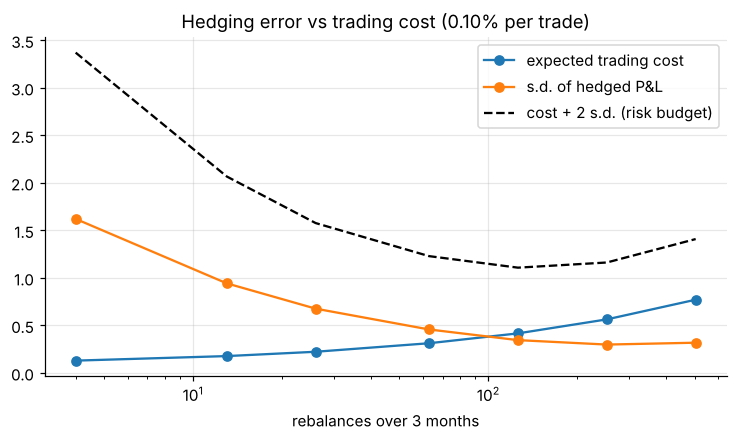

,mean trading cost,s.d. of P&L,mean − 2 s.d.,Leland vol %,Leland price uplift %
rebalances,,,,,
4,0.130,1.622,-3.371,20.317,1.393
13,0.178,0.943,-2.068,20.567,2.495
26,0.224,0.677,-1.578,20.798,3.509
63,0.313,0.458,-1.230,21.229,5.405
126,0.417,0.346,-1.109,21.718,7.555
252,0.564,0.299,-1.163,22.390,10.516
504,0.771,0.319,-1.410,23.309,14.558


In [4]:
cost = 0.001; rows = []
for n in [4, 13, 26, 63, 126, 252, 504]:
    p0 = hedging.delta_hedge_pnl(S0, K, T, r, sig, n, n_paths=30_000, seed=5)
    pc = hedging.delta_hedge_pnl(S0, K, T, r, sig, n, n_paths=30_000, cost=cost, seed=5)
    lv = hedging.leland_vol(sig, 2 * cost, T / n)
    rows.append({"rebalances": n, "mean trading cost": p0.mean() - pc.mean(), "s.d. of P&L": pc.std(),
                 "mean − 2 s.d.": pc.mean() - 2 * pc.std(), "Leland vol %": 100 * lv, "Leland price uplift %": 100 * (bs.price(S0, K, T, r, lv) / prem - 1)})
tc = pd.DataFrame(rows).set_index("rebalances")
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(tc.index, tc["mean trading cost"], "o-", label="expected trading cost"); ax.plot(tc.index, tc["s.d. of P&L"], "o-", label="s.d. of hedged P&L")
ax.plot(tc.index, -tc["mean − 2 s.d."], "k--", label="cost + 2 s.d. (risk budget)"); ax.set_xscale("log"); ax.set_xlabel("rebalances over 3 months"); ax.legend()
ax.set_title("Hedging error vs trading cost (0.10% per trade)")
plt.savefig(IMG / "hedge_costs.png", bbox_inches="tight"); plt.show()
tc.round(3)

## 4. Twenty years of hedged SPY calls
On the first trading day of each month from 2006 to October 2026, sell a 21-trading-day at-the-money call on SPY. It is priced with the **VIX** as implied volatility (the VIX is a 30-day implied volatility for the S&P 500, so this is an approximation for an ATM option) and the 13-week T-bill as the rate. It is then hedged daily at that same implied volatility until expiry. The P&L is measured as a percentage of the spot price at sale.

Theory says the hedged P&L is roughly ½ Γ S² (σ²implied − σ²realised) summed over the month, so it should track the **variance risk premium**: the gap between implied and subsequently realised volatility.

In [5]:
d = pd.read_csv(DATA / "spy_vix_daily.csv", index_col=0, parse_dates=True)
starts = d.groupby(d.index.to_period("M")).head(1).index
rows = []
for t0 in starts:
    i0 = d.index.get_loc(t0); path = d.iloc[i0:i0 + 22]
    if len(path) < 22: continue
    S = path["spy"].to_numpy(); iv = path["vix"].iloc[0] / 100; rr = path["tbill"].iloc[0] / 100
    Tm = 21 / 252; dt = 1 / 252; K0 = S[0]
    premium = bs.price(S[0], K0, Tm, rr, iv); delta = bs.greeks(S[0], K0, Tm, rr, iv).delta; cash = premium - delta * S[0]
    for j in range(1, 22):
        cash *= np.exp(rr * dt); tau = Tm - j * dt
        nd = bs.greeks(S[j], K0, tau, rr, iv).delta if tau > 1e-9 else float(S[j] > K0)
        cash -= (nd - delta) * S[j]; delta = nd
    pnl = cash + delta * S[-1] - max(S[-1] - K0, 0)
    rv = np.log(S[1:] / S[:-1]).std(ddof=0) * np.sqrt(252)
    rows.append({"date": t0, "implied (VIX) %": 100 * iv, "realised %": 100 * rv, "premium %": 100 * premium / S[0], "hedged P&L %": 100 * pnl / S[0]})
m = pd.DataFrame(rows).set_index("date")
m["vol spread (pts)"] = m["implied (VIX) %"] - m["realised %"]
summ = pd.Series({"months": len(m), "average hedged P&L, % of spot": m["hedged P&L %"].mean(), "median": m["hedged P&L %"].median(),
                  "share of months with a profit %": 100 * (m["hedged P&L %"] > 0).mean(), "worst month %": m["hedged P&L %"].min(),
                  "average VIX − realised vol (pts)": m["vol spread (pts)"].mean(), "share of months VIX > realised %": 100 * (m["vol spread (pts)"] > 0).mean(),
                  "correlation of P&L with vol spread": m["hedged P&L %"].corr(m["vol spread (pts)"])})
print(summ.round(3).to_string())
m.nsmallest(5, "hedged P&L %").round(2)

months                                250.000
average hedged P&L, % of spot           0.400
median                                  0.426
share of months with a profit %        82.000
worst month %                          -2.700
average VIX − realised vol (pts)        4.126
share of months VIX > realised %       84.000
correlation of P&L with vol spread      0.865


,implied (VIX) %,realised %,premium %,hedged P&L %,vol spread (pts)
date,,,,,
2020-03-02,33.42,88.74,3.89,-2.70,-55.32
2025-04-01,21.77,50.72,2.68,-2.33,-28.95
2008-09-02,21.99,47.58,2.60,-1.99,-25.59
2008-11-03,53.68,74.73,6.19,-1.47,-21.05
2011-08-01,23.66,47.36,2.73,-1.34,-23.70


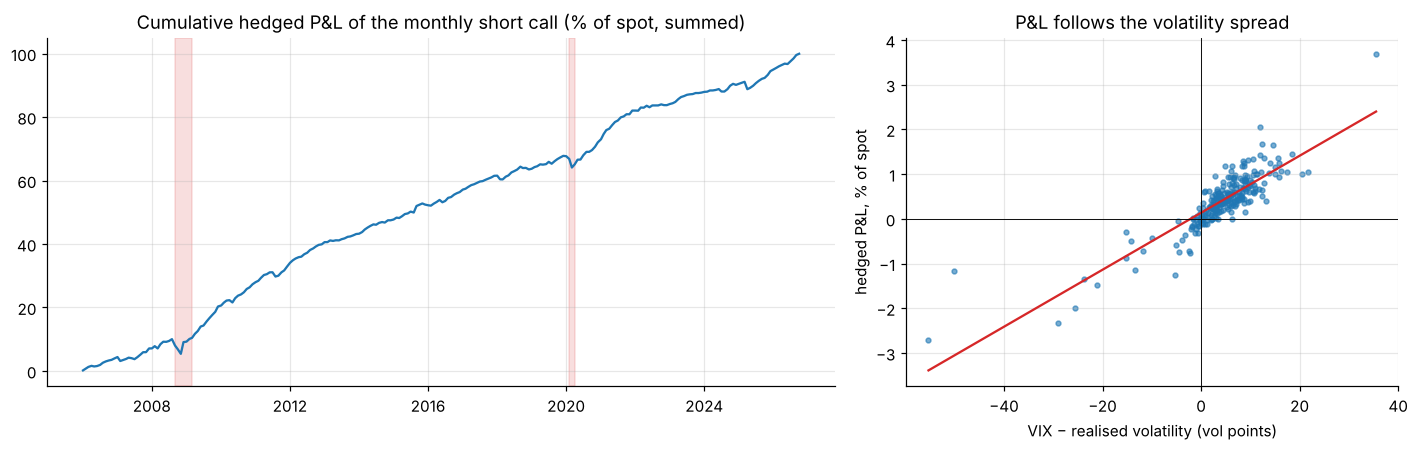

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1.6, 1]})
ax[0].plot(m.index, m["hedged P&L %"].cumsum(), color="C0"); ax[0].set_title("Cumulative hedged P&L of the monthly short call (% of spot, summed)")
for lab, a, b in [("2008", "2008-09", "2009-03"), ("Covid", "2020-02", "2020-04")]: ax[0].axvspan(pd.Timestamp(a), pd.Timestamp(b), color="C3", alpha=0.15)
ax[1].scatter(m["vol spread (pts)"], m["hedged P&L %"], s=10, alpha=0.6)
b = np.polyfit(m["vol spread (pts)"], m["hedged P&L %"], 1); x = np.linspace(m["vol spread (pts)"].min(), m["vol spread (pts)"].max(), 50)
ax[1].plot(x, np.polyval(b, x), "C3"); ax[1].axhline(0, color="k", lw=0.6); ax[1].axvline(0, color="k", lw=0.6)
ax[1].set_xlabel("VIX − realised volatility (vol points)"); ax[1].set_ylabel("hedged P&L, % of spot"); ax[1].set_title("P&L follows the volatility spread")
plt.tight_layout(); plt.savefig(IMG / "spy_hedged_calls.png", bbox_inches="tight"); plt.show()

## Findings
* **Hedging error falls with the square root of the number of rebalances.** The fitted log-log slope is -0.49, against a theoretical -0.5. For a 3-month ATM call, weekly hedging (13 rebalances) leaves a P&L s.d. of 21% of the premium, daily hedging (63) 10%, and four times a day 2.5%. The hedge is fair on average at every frequency.
* **Volatility, not delta, is the real exposure.** Selling at 20% when the stock realises 15% earns about 0.99 per option (the Black-Scholes price difference, 0.985). When it realises 25% the writer loses about 0.99, with a loss in 99.99% of paths. Hedging with the implied rather than the true volatility leaves the average P&L unchanged but roughly doubles its dispersion (s.d. 0.36 vs 0.17 at 15% realised, 0.50 vs 0.28 at 25%).
* **Costs create an optimal frequency.** At 0.10% per trade, expected trading cost rises from 0.13 (4 rebalances) to 0.77 (504) while the P&L s.d. falls. The risk budget (cost + 2 s.d.) is smallest at about 126 rebalances, twice a day. Leland's adjustment prices this in by raising the volatility from 20% to 21.7% at that frequency, a 7.6% higher premium.
* **On SPY, the hedged short call has earned the variance risk premium.** Over 250 months (2006-2026) the VIX was above the volatility realised over the next month 84% of the time, by an average of 4.1 points. The daily-hedged short ATM call made money in 82% of months, with an average of 0.40% of spot a month. P&L correlates 0.87 with the implied-minus-realised spread.
* **The losses come in crises.** The worst months are March 2020 (-2.7%, realised volatility 89% against a VIX of 33), April 2025 (-2.3%), September 2008 and November 2008, and August 2011. All of them are months when realised volatility far exceeded implied. The strategy is short volatility, so it is positively skewed only in calm markets and needs a stop or a hedge for jumps.